In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pdfplumber

# pour afficher toutes les colonnes des tableaux sans les couper
pd.set_option('display.max_columns', None)

In [3]:
# 1. Fichier JSON
airlines = pd.read_json('airlines.json')

# 2. Fichiers Excel
airports = pd.read_excel('airports.xlsx')
flights = pd.read_excel('flights.xlsx')

# 3. Fichier HTML (read_html renvoie une liste de tableaux, on prend le premier avec [0])
planes = pd.read_html('planes.html')[0]

# Vérification rapide des dimensions (lignes, colonnes)
print("airlines :", airlines.shape)
print("airports :", airports.shape)
print("flights  :", flights.shape)
print("planes   :", planes.shape)

airlines : (16, 2)
airports : (1458, 9)
flights  : (252704, 1)
planes   : (3322, 10)


In [4]:
print("--- AIRLINES ---")
display(airlines.head(2))

print("--- AIRPORTS ---")
display(airports.head(2))

print("--- PLANES ---")
display(planes.head(2))

print("--- FLIGHTS ---")
display(flights.head(2))

--- AIRLINES ---


,carrier,name
0,9E,Endeavor Air Inc.
1,AA,American Airlines Inc.


--- AIRPORTS ---


,Unnamed: 0,faa,name,lat,lon,alt,tz,dst,tzone
0,0,04G,Lansdowne Airport,41.130472,-80.619583,1044,-5,A,America/New_York
1,1,06A,Moton Field Municipal Airport,32.460572,-85.680028,264,-6,A,America/Chicago


--- PLANES ---


,Unnamed: 0,tailnum,year,type,manufacturer,model,engines,seats,speed,engine
0,0,N10156,2004.0,Fixed wing multi engine,EMBRAER,EMB-145XR,2,55,NaN,Turbo-fan
1,1,N102UW,1998.0,Fixed wing multi engine,AIRBUS INDUSTRIE,A320-214,2,182,NaN,Turbo-fan


--- FLIGHTS ---


,"year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour"
0,"2021,1,1,517,515,2,830,819,11,UA,1545,N14228,E..."
1,"2021,1,1,533,529,4,850,830,20,UA,1714,N24211,L..."


In [5]:
import io

# 1. Fichier JSON (propre)
airlines = pd.read_json('airlines.json')

# 2. Airports et Planes : on supprime la colonne inutile 'Unnamed: 0'
airports = pd.read_excel('airports.xlsx').drop(columns=['Unnamed: 0'])
planes = pd.read_html('planes.html')[0].drop(columns=['Unnamed: 0'])

# 3. Flights : on transforme la colonne unique de texte en vrai tableau CSV
flights_brut = pd.read_excel('flights.xlsx')
csv_text = flights_brut.columns[0] + '\n' + '\n'.join(flights_brut.iloc[:, 0].astype(str))
flights = pd.read_csv(io.StringIO(csv_text))

# Vérification des nouvelles dimensions
print("airlines :", airlines.shape)
print("airports :", airports.shape)
print("flights  :", flights.shape)
print("planes   :", planes.shape)

airlines : (16, 2)
airports : (1458, 8)
flights  : (252704, 19)
planes   : (3322, 9)


In [9]:
# Extraction de toutes les lignes du PDF weather.pdf
weather_lines = []
with pdfplumber.open('weather.pdf') as pdf:
    for page in pdf.pages:
        text = page.extract_text()
        if text:
        # On découpe le texte ligne par ligne
            weather_lines.extend(text.split('\n'))

# On convertit le tout en DataFrame pandas
weather = pd.read_csv(io.StringIO('\n'.join(weather_lines)))

print("weather :", weather.shape)
display(weather.head(2))

weather : (3299, 15)


,origin,year,month,day,hour,temp,dewp,humid,wind_dir,wind_speed,wind_gust,precip,pressure,visib,time_hour
0,EWR,2021,1,1,0,37.04,21.92,53.97,230,10.357019999999999,11.918651475599997,0.0,1013.9,10.0,2021-01-01T00:00:00Z
1,EWR,2021,1,1,1,37.04,21.92,53.97,230,13.809359999999998,15.891535300799996,0.0,1013,10.0,2021-01-01T01:00:00Z


In [10]:
# Dictionnaire regroupant toutes nos tables
tables = {
    "airlines": airlines,
    "airports": airports,
    "flights": flights,
    "planes": planes,
    "weather": weather
}

# Vérification rapide des dimensions et des colonnes pour chaque table
for name, df in tables.items():
    print(f"=== TABLE : {name.upper()} ===")
    print(f"Dimensions (Lignes, Colonnes) : {df.shape}")
    print(f"Colonnes : {list(df.columns)}")
    print("-" * 50)

=== TABLE : AIRLINES ===
Dimensions (Lignes, Colonnes) : (16, 2)
Colonnes : ['carrier', 'name']
--------------------------------------------------
=== TABLE : AIRPORTS ===
Dimensions (Lignes, Colonnes) : (1458, 8)
Colonnes : ['faa', 'name', 'lat', 'lon', 'alt', 'tz', 'dst', 'tzone']
--------------------------------------------------
=== TABLE : FLIGHTS ===
Dimensions (Lignes, Colonnes) : (252704, 19)
Colonnes : ['year', 'month', 'day', 'dep_time', 'sched_dep_time', 'dep_delay', 'arr_time', 'sched_arr_time', 'arr_delay', 'carrier', 'flight', 'tailnum', 'origin', 'dest', 'air_time', 'distance', 'hour', 'minute', 'time_hour']
--------------------------------------------------
=== TABLE : PLANES ===
Dimensions (Lignes, Colonnes) : (3322, 9)
Colonnes : ['tailnum', 'year', 'type', 'manufacturer', 'model', 'engines', 'seats', 'speed', 'engine']
--------------------------------------------------
=== TABLE : WEATHER ===
Dimensions (Lignes, Colonnes) : (3299, 15)
Colonnes : ['origin', 'year', 'm

In [16]:
# 1. Vérification des types et des valeurs manquantes dans flights
print("--- 1. Analyse de la table FLIGHTS ---")
print("Nombre total de lignes :", len(flights))
print("\nNombre de valeurs 'NA' (sous forme de texte) dans dep_time :", (flights['dep_time'] == 'NA').sum())

# 2. Vérification des aéroports de départ et d'arrivée
print("\n--- 2. Analyse des aéroports ---")
print("Aéroports uniques dans 'origin' (vols) :", flights['origin'].unique())
print("Est-ce que tous les 'origin' sont dans la table airports ?")
print(flights['origin'].isin(airports['faa']).all())

# 3. Vérification rapide des valeurs manquantes globales (NaN)
print("\n--- 3. Valeurs nulles (NaN) par table ---")
print("Flights : \n", flights.isna().sum()[flights.isna().sum() > 0])
print("Airports : \n", airports.isna().sum()[airports.isna().sum() > 0])


print("Valeurs vides ou 'nan' :", flights['dep_time'].isin(['', ' ', 'nan', 'NaN']).sum())

--- 1. Analyse de la table FLIGHTS ---
Nombre total de lignes : 252704

Nombre de valeurs 'NA' (sous forme de texte) dans dep_time : 0

--- 2. Analyse des aéroports ---
Aéroports uniques dans 'origin' (vols) : ['EWR' 'LGA' 'JFK']
Est-ce que tous les 'origin' sont dans la table airports ?
True

--- 3. Valeurs nulles (NaN) par table ---
Flights : 
 Series([], dtype: int64)
Airports : 
 Series([], dtype: int64)
Valeurs vides ou 'nan' : 6481


In [17]:
# --- QUESTION 1 : Statistiques globales ---

# 1. Aéroports en tout, de départ et de destination
nb_airports_total = airports['faa'].nunique()
nb_airports_origin = flights['origin'].nunique()
nb_airports_dest = flights['dest'].nunique()

# 2. Aéroports où on ne passe pas à l'heure d'été (dst == 'N')
nb_no_dst = airports[airports['dst'] == 'N'].shape[0]

# 3. Nombre de fuseaux horaires (colonne tzone)
nb_tzone = airports['tzone'].nunique()

# 4. Compagnies, avions et vols annulés (basé sur notre vérification des valeurs vides/nan)
nb_airlines = airlines['carrier'].nunique()
nb_planes = planes['tailnum'].nunique()
nb_flights_cancelled = flights['dep_time'].isin(['', ' ', 'nan', 'NaN']).sum()

# --- Affichage du rapport final de la Question 1 ---
print("=" * 50)
print("     RAPPORT - QUESTION 1 (MISSION 1)")
print("=" * 50)
print(f"✈️ Aéroports en tout (référentiel) : {nb_airports_total}")
print(f"🛫 Aéroports de départ utilisés     : {nb_airports_origin}")
print(f"🛬 Aéroports de destination utilisés : {nb_airports_dest}")
print("-" * 50)
print(f"⏰ Aéroports sans heure d'été (dst='N'): {nb_no_dst}")
print(f"🌍 Nombre de fuseaux horaires (tzone) : {nb_tzone}")
print("-" * 50)
print(f"🏢 Nombre de compagnies aériennes   : {nb_airlines}")
print(f"✈️ Nombre d'avions uniques (tailnum) : {nb_planes}")
print(f"❌ Nombre de vols annulés           : {nb_flights_cancelled}")
print("=" * 50)

     RAPPORT - QUESTION 1 (MISSION 1)
✈️ Aéroports en tout (référentiel) : 1458
🛫 Aéroports de départ utilisés     : 3
🛬 Aéroports de destination utilisés : 103
--------------------------------------------------
⏰ Aéroports sans heure d'été (dst='N'): 23
🌍 Nombre de fuseaux horaires (tzone) : 10
--------------------------------------------------
🏢 Nombre de compagnies aériennes   : 16
✈️ Nombre d'avions uniques (tailnum) : 3322
❌ Nombre de vols annulés           : 6481


In [19]:
# --- QUESTION 2 : Analyse complète des départs, destinations et avions ---

total_flights = len(flights)

# 1. Aéroports de départ (avec nom complet et pourcentage)
print("=" * 60)
print("🛫 AÉROPORTS DE DÉPART")
print("=" * 60)
origin_counts = flights['origin'].value_counts()
for orig, count in origin_counts.items():
    pct = (count / total_flights) * 100
    name = airports[airports['faa'] == orig]['name'].values[0] if not airports[airports['faa'] == orig].empty else orig
    print(f"- {orig} ({name}) : {count:,} vols ({pct:.2f}%)")

# 2. Top 10 des destinations les plus prisées (avec nom complet et pourcentage)
print("\n" + "=" * 60)
print("🏆 TOP 10 DESTINATIONS LES PLUS PRISÉES")
print("=" * 60)
top_dest = flights['dest'].value_counts().head(10)
for dest, count in top_dest.items():
    pct = (count / total_flights) * 100
    name = airports[airports['faa'] == dest]['name'].values[0] if not airports[airports['faa'] == dest].empty else dest
    print(f"- {dest} ({name}) : {count:,} vols ({pct:.2f}%)")

# 3. Top 10 des destinations les moins prisées (avec nom complet et pourcentage)
print("\n" + "=" * 60)
print("📉 TOP 10 DESTINATIONS LES MOINS PRISÉES")
print("=" * 60)
bottom_dest = flights['dest'].value_counts().tail(10)
for dest, count in bottom_dest.items():
    pct = (count / total_flights) * 100
    name = airports[airports['faa'] == dest]['name'].values[0] if not airports[airports['faa'] == dest].empty else dest
    print(f"- {dest} ({name}) : {count} vol(s) ({pct:.4f}%)")

# 4. Top 10 des avions qui ont le plus décollé
print("\n" + "=" * 60)
print("✈️ TOP 10 AVIONS QUI ONT LE PLUS DÉCOLLÉ")
print("=" * 60)
top_planes = flights['tailnum'].value_counts().head(10)
for plane, count in top_planes.items():
    print(f"- Immatriculation {plane} : {count} décollages")

# 5. Top 10 des avions qui ont le moins décollé
print("\n" + "=" * 60)
print("✈️ TOP 10 AVIONS QUI ONT LE MOINS DÉCOLLÉ")
print("=" * 60)
valid_planes = flights[flights['tailnum'].notna() & (flights['tailnum'] != '') & (flights['tailnum'] != 'NA')]
bottom_planes = valid_planes['tailnum'].value_counts().tail(10)
for plane, count in bottom_planes.items():
    print(f"- Immatriculation {plane} : {count} décollage(s)")
print("=" * 60)

🛫 AÉROPORTS DE DÉPART
- EWR (Newark Liberty Intl) : 91,241 vols (36.11%)
- JFK (John F Kennedy Intl) : 83,119 vols (32.89%)
- LGA (La Guardia) : 78,344 vols (31.00%)

🏆 TOP 10 DESTINATIONS LES PLUS PRISÉES
- ATL (Hartsfield Jackson Atlanta Intl) : 12,946 vols (5.12%)
- ORD (Chicago Ohare Intl) : 12,654 vols (5.01%)
- LAX (Los Angeles Intl) : 11,895 vols (4.71%)
- BOS (General Edward Lawrence Logan Intl) : 11,560 vols (4.57%)
- MCO (Orlando Intl) : 10,637 vols (4.21%)
- CLT (Charlotte Douglas Intl) : 10,448 vols (4.13%)
- SFO (San Francisco Intl) : 9,729 vols (3.85%)
- FLL (Fort Lauderdale Hollywood Intl) : 9,443 vols (3.74%)
- MIA (Miami Intl) : 8,938 vols (3.54%)
- DCA (Ronald Reagan Washington Natl) : 7,386 vols (2.92%)

📉 TOP 10 DESTINATIONS LES MOINS PRISÉES
- CHO (Charlottesville-Albemarle) : 31 vol(s) (0.0123%)
- JAC (Jackson Hole Airport) : 25 vol(s) (0.0099%)
- BZN (Gallatin Field) : 20 vol(s) (0.0079%)
- PSP (Palm Springs Intl) : 19 vol(s) (0.0075%)
- EYW (Key West Intl) : 17 

     DESTINATIONS DESSERVIES PAR COMPAGNIE
- ExpressJet Airlines Inc. (EV) : 61 destinations
- Endeavor Air Inc. (9E) : 47 destinations
- United Air Lines Inc. (UA) : 45 destinations
- JetBlue Airways (B6) : 42 destinations
- Delta Air Lines Inc. (DL) : 40 destinations
- Envoy Air (MQ) : 20 destinations
- American Airlines Inc. (AA) : 19 destinations
- Southwest Airlines Co. (WN) : 11 destinations
- Virgin America (VX) : 5 destinations
- US Airways Inc. (US) : 5 destinations
- SkyWest Airlines Inc. (OO) : 4 destinations
- AirTran Airways Corporation (FL) : 3 destinations
- Mesa Airlines Inc. (YV) : 3 destinations
- Alaska Airlines Inc. (AS) : 1 destinations
- Frontier Airlines Inc. (F9) : 1 destinations
- Hawaiian Airlines Inc. (HA) : 1 destinations


C:\Users\rharb\AppData\Local\Temp\ipykernel_15260\3037443749.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


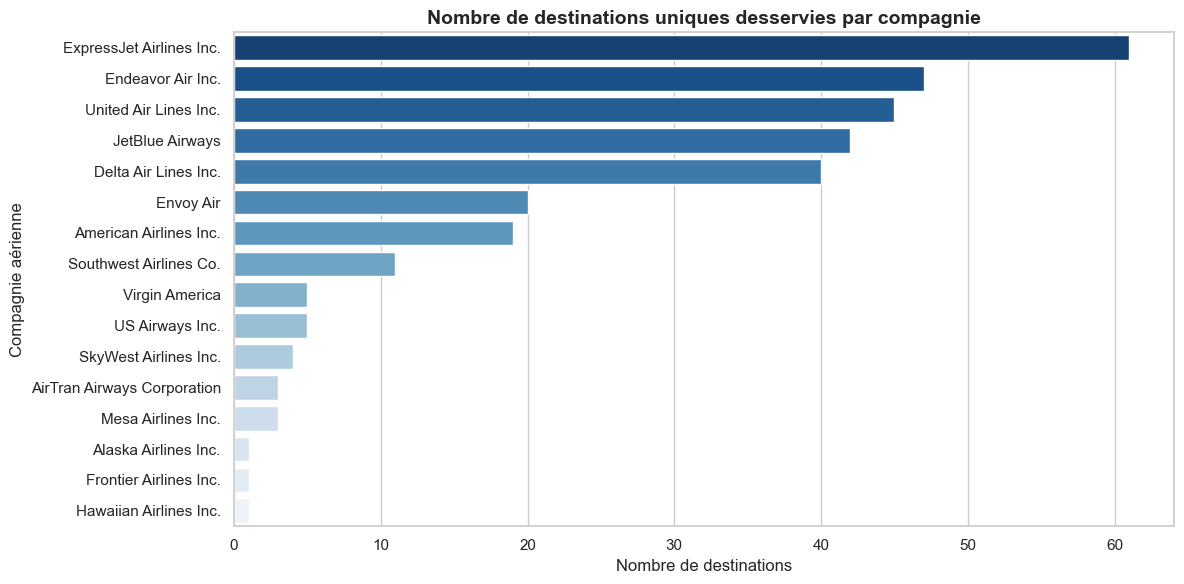

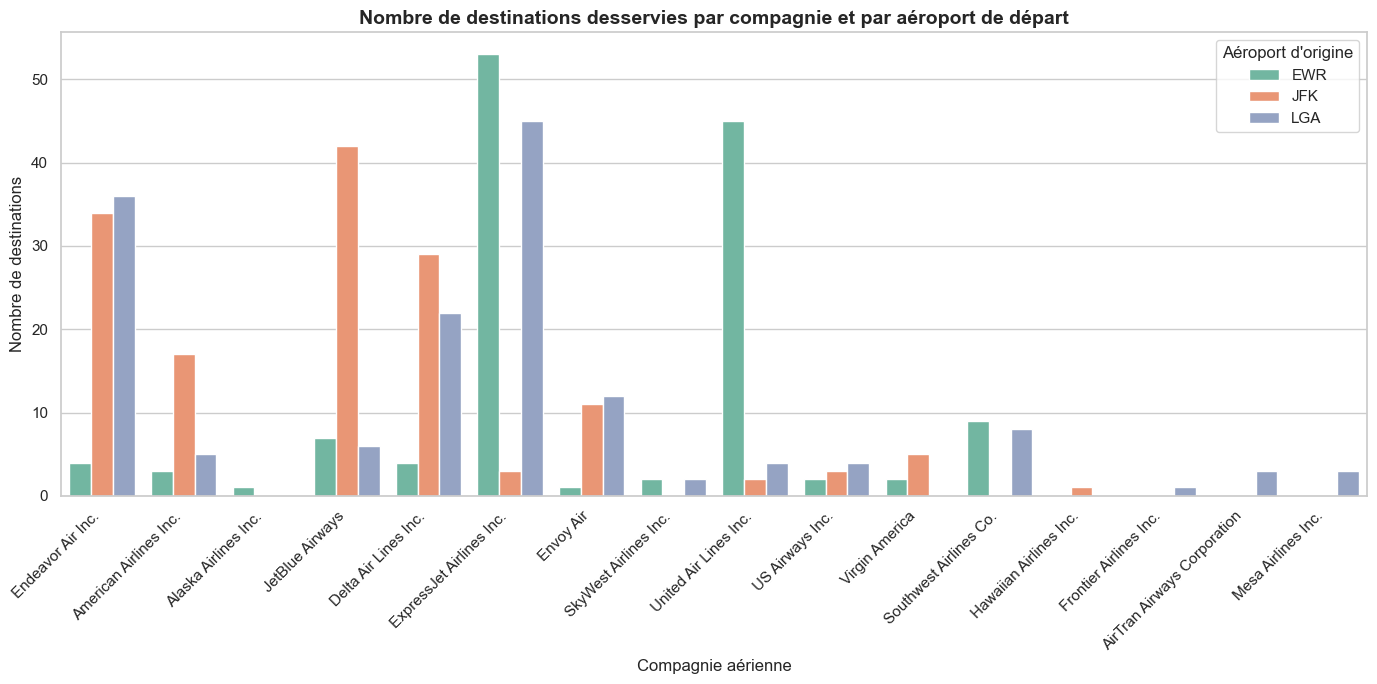

In [20]:
# QUESTION 3
# Combien chaque compagnie a desservi de destination ;
# combien chaque compagnie a desservie de destination par aéroport d’origine. 
# Réaliser les graphiques adéquats qui synthétisent ces informations ?

import matplotlib.pyplot as plt
import seaborn as sns

# Configuration esthétique des graphiques
sns.set_theme(style="whitegrid")

# --- 1. Calculs : Destinations par compagnie ---
dest_per_carrier = flights.groupby('carrier')['dest'].nunique().reset_index()
dest_per_carrier = dest_per_carrier.merge(airlines, on='carrier', how='left')
dest_per_carrier = dest_per_carrier.sort_values(by='dest', ascending=False)

# --- 2. Calculs : Destinations par compagnie et par aéroport d'origine ---
dest_per_origin_carrier = flights.groupby(['origin', 'carrier'])['dest'].nunique().reset_index()
dest_per_origin_carrier = dest_per_origin_carrier.merge(airlines, on='carrier', how='left')

# --- AFFICHAGE TEXTUEL ---
print("=" * 60)
print("     DESTINATIONS DESSERVIES PAR COMPAGNIE")
print("=" * 60)
for idx, row in dest_per_carrier.iterrows():
    print(f"- {row['name']} ({row['carrier']}) : {row['dest']} destinations")

# --- GRAPHIQUE 1 : Bar chart des destinations par compagnie ---
plt.figure(figsize=(12, 6))
sns.barplot(
    data=dest_per_carrier, 
    x='dest', 
    y='name', 
    palette='Blues_r'
)
plt.title("Nombre de destinations uniques desservies par compagnie", fontsize=14, fontweight='bold')
plt.xlabel("Nombre de destinations", fontsize=12)
plt.ylabel("Compagnie aérienne", fontsize=12)
plt.tight_layout()
plt.show()

# --- GRAPHIQUE 2 : Bar chart groupé par aéroport d'origine ---
plt.figure(figsize=(14, 7))
sns.barplot(
    data=dest_per_origin_carrier, 
    x='name', 
    y='dest', 
    hue='origin', 
    palette='Set2'
)
plt.title("Nombre de destinations desservies par compagnie et par aéroport de départ", fontsize=14, fontweight='bold')
plt.xlabel("Compagnie aérienne", fontsize=12)
plt.ylabel("Nombre de destinations", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title="Aéroport d'origine")
plt.tight_layout()
plt.show()

In [21]:
# QUESTION 4

# Trouver tous les vols ayant atterri à Houston (IAH ou HOU) ? 
# Combien de vols partent de NYC airports vers Seattle, 
# combien de compagnies desservent cette destination et combien d’avions “uniques” ?  



# --- ANALYSE : Houston et Seattle ---

# 1. Vols ayant atterri à Houston (IAH ou HOU)
houston_flights = flights[flights['dest'].isin(['IAH', 'HOU'])]
print(f"✈️ Nombre de vols ayant atterri à Houston (IAH ou HOU) : {len(houston_flights):,}")

# 2. Vols partant de NYC vers Seattle (SEA)
sea_flights = flights[flights['dest'] == 'SEA']
print(f"🛫 Nombre de vols de NYC vers Seattle (SEA) : {len(sea_flights):,}")

# 3. Compagnies desservant Seattle
nb_carriers_sea = sea_flights['carrier'].nunique()
carriers_codes = sea_flights['carrier'].unique()
carriers_names = airlines[airlines['carrier'].isin(carriers_codes)]['name'].tolist()

print(f"🏢 Nombre de compagnies desservant Seattle : {nb_carriers_sea}")
print(f"   Compagnies : {carriers_names}")

# 4. Avions 'uniques' desservant Seattle
nb_planes_sea = sea_flights['tailnum'].dropna().nunique()
print(f"✈️ Nombre d'avions uniques desservant Seattle : {nb_planes_sea:,}")

✈️ Nombre de vols ayant atterri à Houston (IAH ou HOU) : 6,958
🛫 Nombre de vols de NYC vers Seattle (SEA) : 2,736
🏢 Nombre de compagnies desservant Seattle : 5
   Compagnies : ['American Airlines Inc.', 'Alaska Airlines Inc.', 'JetBlue Airways', 'Delta Air Lines Inc.', 'United Air Lines Inc.']
✈️ Nombre d'avions uniques desservant Seattle : 857


In [22]:
# QUESTION 5

# Trouver le nombre de vols par destination ? 
# Trier les vols suivant la destination, l’aéroport d’origine,
# la compagnie dans un ordre alphabétique croissant (en réalisant les jointures nécessaires pour obtenir les noms explicites des aéroports) ? 


# --- 1. Nombre de vols par destination (avec noms explicites) ---
flights_per_dest = flights.groupby('dest').size().reset_index(name='nb_vols')
# Jointure avec la table airports pour récupérer le nom complet de la destination
flights_per_dest = flights_per_dest.merge(
    airports[['faa', 'name']], 
    left_on='dest', 
    right_on='faa', 
    how='left'
).drop(columns=['faa']).rename(columns={'name': 'dest_name'})

# Réorganisation des colonnes pour plus de clarté
flights_per_dest = flights_per_dest[['dest', 'dest_name', 'nb_vols']].sort_values(by='nb_vols', ascending=False)

print("=" * 60)
print("     NOMBRE DE VOLS PAR DESTINATION (TOP 10)")
print("=" * 60)
print(flights_per_dest.head(10).to_string(index=False))


# --- 2. Tri des vols par destination, origine et compagnie (noms explicites, ordre alphabétique) ---
# Sélection et jointures pour récupérer tous les noms explicites
flights_detailed = flights[['dest', 'origin', 'carrier', 'flight', 'year', 'month', 'day']].copy()

# Jointure pour l'aéroport de destination
flights_detailed = flights_detailed.merge(
    airports[['faa', 'name']], left_on='dest', right_on='faa', how='left'
).drop(columns=['faa']).rename(columns={'name': 'dest_full_name'})

# Jointure pour l'aéroport d'origine
flights_detailed = flights_detailed.merge(
    airports[['faa', 'name']], left_on='origin', right_on='faa', how='left'
).drop(columns=['faa']).rename(columns={'name': 'origin_full_name'})

# Jointure pour la compagnie aérienne
flights_detailed = flights_detailed.merge(
    airlines, left_on='carrier', right_on='carrier', how='left'
).rename(columns={'name': 'carrier_full_name'})

# Tri alphabétique croissant : 1. Destination, 2. Aéroport d'origine, 3. Compagnie
flights_sorted = flights_detailed.sort_values(
    by=['dest', 'origin', 'carrier'], 
    ascending=[True, True, True]
)

print("\n" + "=" * 60)
print("     VOLS TRIÉS (DESTINATION → ORIGINE → COMPAGNIE)")
print("=" * 60)
# Aperçu des 10 premières lignes triées
cols_to_show = ['dest', 'dest_full_name', 'origin', 'origin_full_name', 'carrier_full_name', 'flight']
print(flights_sorted[cols_to_show].head(10).to_string(index=False))

     NOMBRE DE VOLS PAR DESTINATION (TOP 10)
dest                          dest_name  nb_vols
 ATL    Hartsfield Jackson Atlanta Intl    12946
 ORD                 Chicago Ohare Intl    12654
 LAX                   Los Angeles Intl    11895
 BOS General Edward Lawrence Logan Intl    11560
 MCO                       Orlando Intl    10637
 CLT             Charlotte Douglas Intl    10448
 SFO                 San Francisco Intl     9729
 FLL     Fort Lauderdale Hollywood Intl     9443
 MIA                         Miami Intl     8938
 DCA      Ronald Reagan Washington Natl     7386

     VOLS TRIÉS (DESTINATION → ORIGINE → COMPAGNIE)
dest                    dest_full_name origin    origin_full_name carrier_full_name  flight
 ABQ Albuquerque International Sunport    JFK John F Kennedy Intl   JetBlue Airways      65
 ABQ Albuquerque International Sunport    JFK John F Kennedy Intl   JetBlue Airways      65
 ABQ Albuquerque International Sunport    JFK John F Kennedy Intl   JetBlue Airways    

In [23]:
# QUESTION 6


# Quelles sont les compagnies qui n'opèrent pas sur tous les aéroports d’origine ? 
# Quelles sont les compagnies qui desservent l’ensemble de destinations ? 
# Faire un tableau où l’on récupère l’ensemble des origines et des destinations pour l’ensemble des compagnies. 


import pandas as pd

# --- 1. Compagnies qui n'opèrent pas sur tous les aéroports d'origine ---
# Les 3 aéroports de départ totaux dans la base
all_origins = set(flights['origin'].unique())

# On liste les origines desservies par chaque compagnie
origins_per_carrier = flights.groupby('carrier')['origin'].unique().apply(set)

# Compagnies qui n'ont pas la totalité des 3 origines
carriers_not_all_origins = origins_per_carrier[origins_per_carrier != all_origins].index.tolist()
carriers_not_all_origins_names = airlines[airlines['carrier'].isin(carriers_not_all_origins)]['name'].tolist()

print("=" * 60)
print("🛫 COMPAGNIES N'OPÉRANT PAS SUR TOUS LES AÉROPORTS D'ORIGINE")
print("=" * 60)
print(carriers_not_all_origins_names)


# --- 2. Compagnies qui desservent l'ensemble des destinations ---
# L'ensemble de toutes les destinations uniques de la base
all_destinations = set(flights['dest'].unique())
total_dest_count = len(all_destinations)

# Destinations desservies par chaque compagnie
dest_per_carrier_set = flights.groupby('carrier')['dest'].unique().apply(set)

# Trouver la ou les compagnies qui desservent TOUTES les destinations
carriers_all_dest = dest_per_carrier_set[dest_per_carrier_set == all_destinations].index.tolist()
carriers_all_dest_names = airlines[airlines['carrier'].isin(carriers_all_dest)]['name'].tolist()

print("\n" + "=" * 60)
print("🏆 COMPAGNIES DESSERVANT L'ENSEMBLE DES DESTINATIONS")
print("=" * 60)
if carriers_all_dest_names:
    print(carriers_all_dest_names)
else:
    print("Aucune compagnie ne dessert à elle seule l'intégralité des 103 destinations de la base.")
    # Affichons celle qui en dessert le plus pour être précis
    max_dest = dest_per_carrier_set.apply(len).max()
    top_carrier_code = dest_per_carrier_set[dest_per_carrier_set.apply(len) == max_dest].index[0]
    top_carrier_name = airlines[airlines['carrier'] == top_carrier_code]['name'].values[0]
    print(f"La compagnie couvrant le plus de destinations est {top_carrier_name} avec {max_dest} destinations.")


# --- 3. Tableau de synthèse (Origines, Destinations, Compagnies) ---
# On croise chaque origine, destination et compagnie présente sur ces liaisons
synth_table = flights[['origin', 'dest', 'carrier']].drop_duplicates().sort_values(by=['origin', 'dest', 'carrier'])

# Ajout des noms explicites
synth_table = synth_table.merge(airports[['faa', 'name']], left_on='origin', right_on='faa', how='left').drop(columns=['faa']).rename(columns={'name': 'origin_name'})
synth_table = synth_table.merge(airports[['faa', 'name']], left_on='dest', right_on='faa', how='left').drop(columns=['faa']).rename(columns={'name': 'dest_name'})
synth_table = synth_table.merge(airlines, left_on='carrier', right_on='carrier', how='left').rename(columns={'name': 'carrier_name'})

# Réorganisation des colonnes
synth_table = synth_table[['origin', 'origin_name', 'dest', 'dest_name', 'carrier', 'carrier_name']]

print("\n" + "=" * 60)
print("     TABLEAU DE SYNTHÈSE (ORIGINES → DESTINATIONS → COMPAGNIES)")
print("=" * 60)
print(synth_table.head(15).to_string(index=False))

🛫 COMPAGNIES N'OPÉRANT PAS SUR TOUS LES AÉROPORTS D'ORIGINE
['Alaska Airlines Inc.', 'Frontier Airlines Inc.', 'AirTran Airways Corporation', 'Hawaiian Airlines Inc.', 'SkyWest Airlines Inc.', 'Virgin America', 'Southwest Airlines Co.', 'Mesa Airlines Inc.']

🏆 COMPAGNIES DESSERVANT L'ENSEMBLE DES DESTINATIONS
Aucune compagnie ne dessert à elle seule l'intégralité des 103 destinations de la base.
La compagnie couvrant le plus de destinations est ExpressJet Airlines Inc. avec 61 destinations.

     TABLEAU DE SYNTHÈSE (ORIGINES → DESTINATIONS → COMPAGNIES)
origin         origin_name dest                          dest_name carrier             carrier_name
   EWR Newark Liberty Intl  ALB                        Albany Intl      EV ExpressJet Airlines Inc.
   EWR Newark Liberty Intl  ATL    Hartsfield Jackson Atlanta Intl      9E        Endeavor Air Inc.
   EWR Newark Liberty Intl  ATL    Hartsfield Jackson Atlanta Intl      DL     Delta Air Lines Inc.
   EWR Newark Liberty Intl  ATL    Har

In [24]:
# Question 7
# Quelles sont les destinations qui sont exclusives à certaines compagnies ? 


# --- Analyse des destinations exclusives à une seule compagnie ---

# 1. Compter le nombre de compagnies uniques (`carrier`) par destination (`dest`)
dest_carrier_count = flights.groupby('dest')['carrier'].nunique().reset_index(name='nb_carriers')

# 2. Filtrer pour ne garder que les destinations desservies par une seule compagnie (nb_carriers == 1)
exclusive_destinations = dest_carrier_count[dest_carrier_count['nb_carriers'] == 1]

# 3. Récupérer les détails (compagnie associée à chaque destination exclusive)
exclusive_details = flights[flights['dest'].isin(exclusive_destinations['dest'])][['dest', 'carrier']].drop_duplicates()

# 4. Effectuer les jointures pour obtenir les noms explicites (aéroports et compagnies)
exclusive_details = exclusive_details.merge(
    airports[['faa', 'name']], left_on='dest', right_on='faa', how='left'
).drop(columns=['faa']).rename(columns={'name': 'dest_name'})

exclusive_details = exclusive_details.merge(
    airlines, left_on='carrier', right_on='carrier', how='left'
).rename(columns={'name': 'carrier_name'})

# 5. Tri par nom de compagnie pour une meilleure lisibilité
exclusive_details = exclusive_details[['dest', 'dest_name', 'carrier', 'carrier_name']].sort_values(by='carrier_name')

print("=" * 70)
print(f"     DESTINATIONS EXCLUSIVES ({len(exclusive_details)} trouvées)")
print("=" * 70)
print(exclusive_details.to_string(index=False))



     DESTINATIONS EXCLUSIVES (29 trouvées)
dest                         dest_name carrier                carrier_name
 CAK     Akron Canton Regional Airport      FL AirTran Airways Corporation
 EYW                     Key West Intl      DL        Delta Air Lines Inc.
 LEX                        Blue Grass      9E           Endeavor Air Inc.
 CRW                            Yeager      MQ                   Envoy Air
 OKC                 Will Rogers World      EV    ExpressJet Airlines Inc.
 SBN                   South Bend Rgnl      EV    ExpressJet Airlines Inc.
 ILM                   Wilmington Intl      EV    ExpressJet Airlines Inc.
 BHM                   Birmingham Intl      EV    ExpressJet Airlines Inc.
 PVD      Theodore Francis Green State      EV    ExpressJet Airlines Inc.
 TUL                        Tulsa Intl      EV    ExpressJet Airlines Inc.
 CHO         Charlottesville-Albemarle      EV    ExpressJet Airlines Inc.
 GSO                    Piedmont Triad      EV    Express

In [25]:
 # Question 8

# Filtrer le vol pour trouver ceux exploités par United, American ou Delta ? 


# --- Filtrer les vols exploités par United, American ou Delta ---

# 1. Liste des codes IATA des compagnies ciblées
target_carriers = ['UA', 'AA', 'DL']

# 2. Filtrer la table flights
flights_major = flights[flights['carrier'].isin(target_carriers)].copy()

# 3. Effectuer la jointure avec la table airlines pour récupérer le nom explicite de la compagnie
flights_major = flights_major.merge(
    airlines, 
    on='carrier', 
    how='left'
).rename(columns={'name': 'carrier_name'})

# 4. Afficher quelques statistiques de contrôle
print("=" * 60)
print(f"     VOLS FILTRÉS (UNITED, AMERICAN, DELTA)")
print("=" * 60)
print(f"Nombre total de vols pour ces 3 compagnies : {len(flights_major):,}")
print("\nRépartition par compagnie :")
print(flights_major['carrier_name'].value_counts())

# 5. Aperçu des premières lignes du DataFrame filtré
print("\n" + "=" * 60)
print("     APERÇU DES VOLS FILTRÉS")
print("=" * 60)
cols_to_show = ['year', 'month', 'day', 'dep_time', 'origin', 'dest', 'carrier_name', 'flight']
print(flights_major[cols_to_show].head(10).to_string(index=False))

     VOLS FILTRÉS (UNITED, AMERICAN, DELTA)
Nombre total de vols pour ces 3 compagnies : 104,742

Répartition par compagnie :
carrier_name
United Air Lines Inc.     44165
Delta Air Lines Inc.      35975
American Airlines Inc.    24602
Name: count, dtype: int64

     APERÇU DES VOLS FILTRÉS
 year  month  day dep_time origin dest           carrier_name  flight
 2021      1    1      517    EWR  IAH  United Air Lines Inc.    1545
 2021      1    1      533    LGA  IAH  United Air Lines Inc.    1714
 2021      1    1      542    JFK  MIA American Airlines Inc.    1141
 2021      1    1      554    LGA  ATL   Delta Air Lines Inc.     461
 2021      1    1      554    EWR  ORD  United Air Lines Inc.    1696
 2021      1    1      558    LGA  ORD American Airlines Inc.     301
 2021      1    1      558    JFK  LAX  United Air Lines Inc.     194
 2021      1    1      558    EWR  SFO  United Air Lines Inc.    1124
 2021      1    1      559    LGA  DFW American Airlines Inc.     707
 2021    

In [26]:
# --- AUDIT DES DONNÉES MANQUANTES : TABLE WEATHER ---

# 1. Compter les valeurs manquantes (NaN) par colonne dans weather
missing_weather = weather.isnull().sum()
missing_weather_pct = (weather.isnull().mean() * 100).round(2)

df_audit_weather = pd.DataFrame({
    'Valeurs Manquantes': missing_weather,
    'Pourcentage (%)': missing_weather_pct
})

print("=" * 60)
print("     BILAN DES VALEURS MANQUANTES DANS WEATHER")
print("=" * 60)
print(df_audit_weather[df_audit_weather['Valeurs Manquantes'] > 0])

# 2. Vérification des doublons sur la clé primaire composite 
# (origin, year, month, day, hour)
pk_cols = ['origin', 'year', 'month', 'day', 'hour']
duplicates_count = weather.duplicated(subset=pk_cols).sum()

print("\n" + "=" * 60)
print("     CONTRÔLE DE LA CLÉ PRIMAIRE COMPOSITE")
print("=" * 60)
print(f"Nombre de lignes en double sur la clé ({', '.join(pk_cols)}) : {duplicates_count}")

if duplicates_count > 0:
    print("⚠️ Attention : Des doublons existent sur la clé composite, ce qui empêche d'en faire une clé primaire stricte sans nettoyage préalable !")
else:
    print("✅ Aucun doublon détecté : la clé composite est valide et unique.")

     BILAN DES VALEURS MANQUANTES DANS WEATHER
Empty DataFrame
Columns: [Valeurs Manquantes, Pourcentage (%)]
Index: []

     CONTRÔLE DE LA CLÉ PRIMAIRE COMPOSITE
Nombre de lignes en double sur la clé (origin, year, month, day, hour) : 0
✅ Aucun doublon détecté : la clé composite est valide et unique.
